In [8]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [9]:
DATA_PATH = "D://Class notes//organic_farming_suitability_1000_source_calibrated (1).csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully.
Rows: 1000
Columns: 24


,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,...,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,...,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,...,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,...,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,...,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable


In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Dataset shape: (1000, 24)

Column names:
['Sample_ID', 'State', 'Soil_Type', 'Crop', 'pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage', 'Years_Chemical_Input', 'Suitability_Score', 'Organic_Farming_Suitability']

Data types:


Sample_ID                       object
State                           object
Soil_Type                       object
Crop                            object
pH                             float64
Organic_Carbon_pct             float64
Available_N_kg_ha              float64
Available_P_kg_ha              float64
Available_K_kg_ha              float64
Available_S_mg_kg              float64
Available_Zn_mg_kg             float64
Available_Fe_mg_kg             float64
Available_Mn_mg_kg             float64
Available_Cu_mg_kg             float64
Available_B_mg_kg              float64
EC_dS_m                        float64
Annual_Rainfall_mm             float64
Mean_Temperature_C             float64
Soil_Moisture_pct              float64
Previous_Fertilizer_Usage       object
Previous_Pesticide_Usage        object
Years_Chemical_Input             int64
Suitability_Score              float64
Organic_Farming_Suitability     object
dtype: object


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    1000 non-null   object 
 1   State                        1000 non-null   object 
 2   Soil_Type                    1000 non-null   object 
 3   Crop                         1000 non-null   object 
 4   pH                           1000 non-null   float64
 5   Organic_Carbon_pct           1000 non-null   float64
 6   Available_N_kg_ha            1000 non-null   float64
 7   Available_P_kg_ha            1000 non-null   float64
 8   Available_K_kg_ha            1000 non-null   float64
 9   Available_S_mg_kg            1000 non-null   float64
 10  Available_Zn_mg_kg           1000 non-null   float64
 11  Available_Fe_mg_kg           1000 non-null   float64
 12  Available_Mn_mg_kg           1000 non-null   float64
 1

,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,Available_Fe_mg_kg,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Years_Chemical_Input,Suitability_Score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,6.915940,0.724501,259.016700,29.549400,254.25270,15.801290,0.785150,20.480830,9.191230,0.774470,0.664450,0.416374,958.61930,26.989700,28.409200,5.234000,52.279100
std,0.754045,0.346696,91.347824,16.859065,126.79943,6.615834,0.366406,12.802683,5.361124,0.385222,0.360343,0.245273,437.40239,3.448027,8.941545,4.037021,13.259376
min,4.800000,0.189000,80.000000,3.000000,40.00000,3.000000,0.150000,2.990000,1.440000,0.170000,0.130000,0.050000,180.00000,17.000000,8.000000,0.000000,4.500000
25%,6.400000,0.481000,194.075000,16.475000,165.70000,11.282500,0.530000,11.915000,5.490000,0.517500,0.430000,0.247750,646.12500,24.575000,22.800000,2.000000,43.575000
50%,6.925000,0.653500,257.300000,29.100000,242.35000,15.540000,0.710000,17.335000,7.765000,0.695000,0.580000,0.357000,928.90000,26.900000,28.400000,4.000000,52.750000
75%,7.420000,0.877250,315.825000,40.825000,345.92500,20.257500,0.960000,25.312500,11.625000,0.930000,0.800000,0.526250,1255.67500,29.400000,34.325000,6.000000,60.400000
max,9.190000,2.500000,588.100000,86.300000,653.20000,39.060000,4.000000,80.000000,40.000000,4.000000,2.730000,1.926000,2240.60000,36.000000,55.000000,15.000000,89.300000



Categorical summary:


,Sample_ID,State,Soil_Type,Crop,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Organic_Farming_Suitability
count,1000,1000,1000,1000,1000,1000,1000
unique,1000,15,7,12,3,3,2
top,OF-0001,Madhya Pradesh,Alluvial,Maize,Chemical,Moderate,Not Suitable
freq,1,81,279,110,402,411,577


In [6]:
df.columns = df.columns.str.strip()
df = df.replace([np.inf, -np.inf], np.nan)

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Sample_ID values:", df["Sample_ID"].duplicated().sum())

# Remove exact duplicate rows only.
df = df.drop_duplicates().copy()

print("Shape after removing exact duplicate rows:", df.shape)
print("\nTarget labels:")
display(df["Organic_Farming_Suitability"].value_counts(dropna=False))

Missing values per column:


,Missing_Count
Sample_ID,0
State,0
Soil_Type,0
Crop,0
pH,0
Organic_Carbon_pct,0
Available_N_kg_ha,0
Available_P_kg_ha,0
Available_K_kg_ha,0
Available_S_mg_kg,0


Duplicate rows: 0
Duplicate Sample_ID values: 0
Shape after removing exact duplicate rows: (1000, 24)

Target labels:


Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64

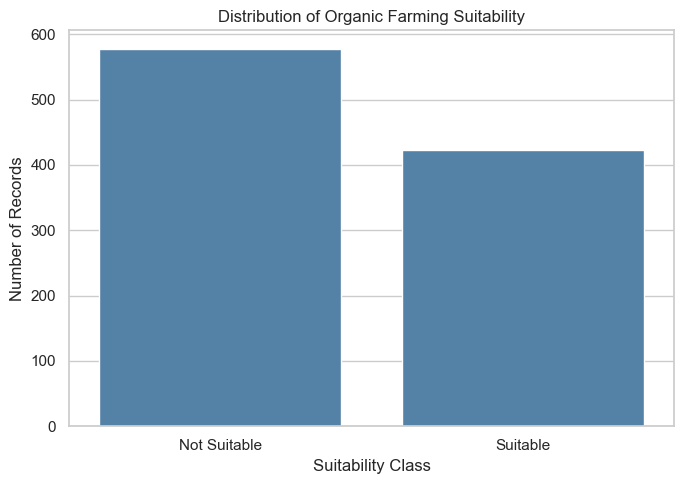

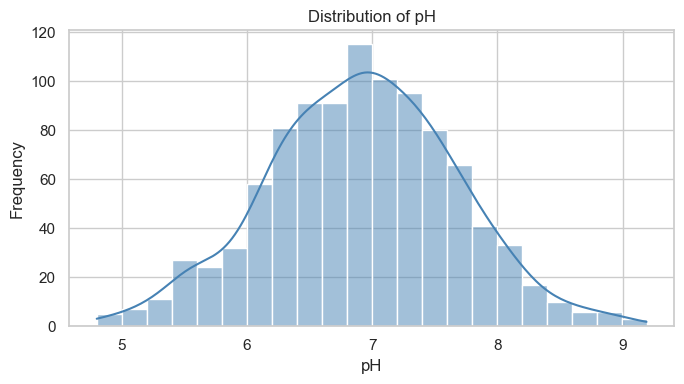

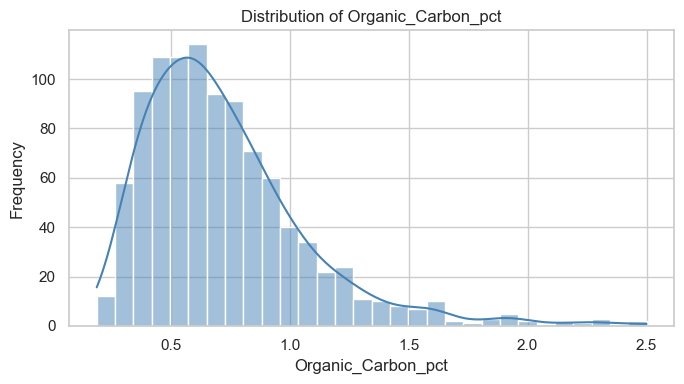

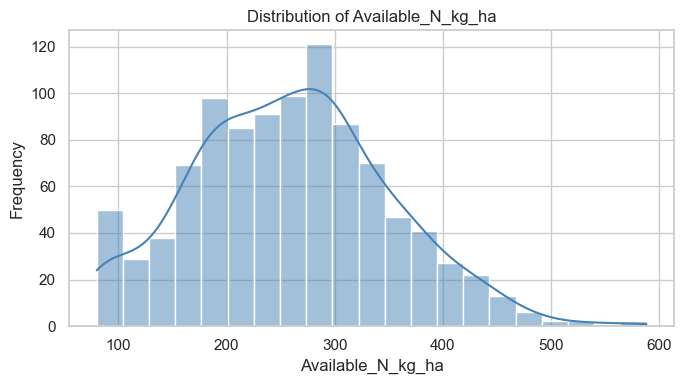

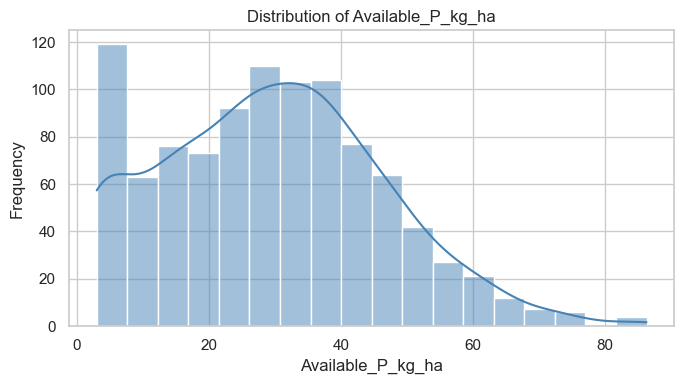

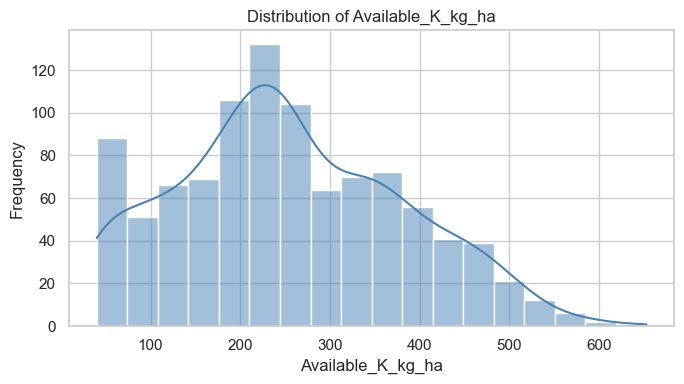

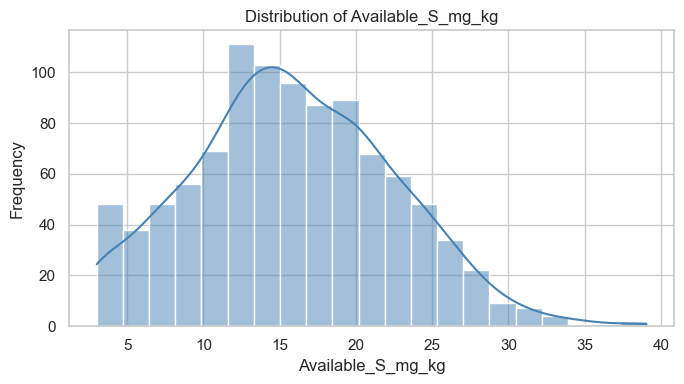

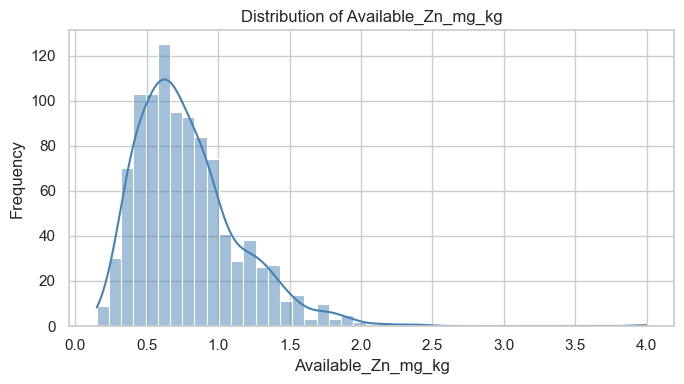

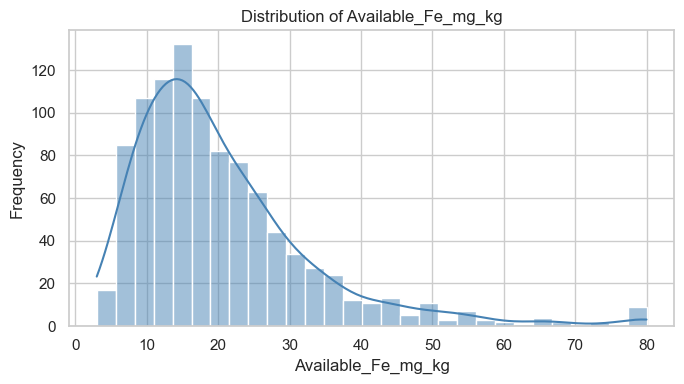

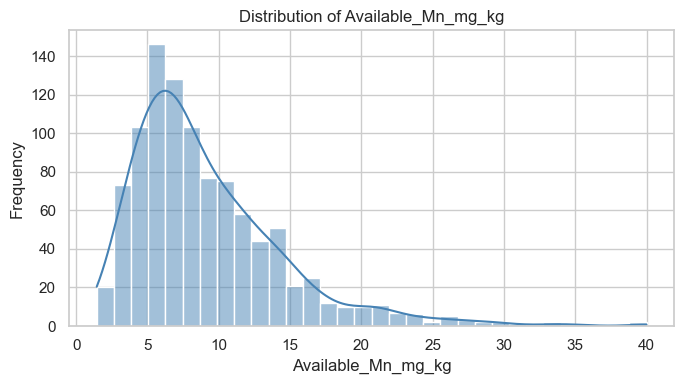

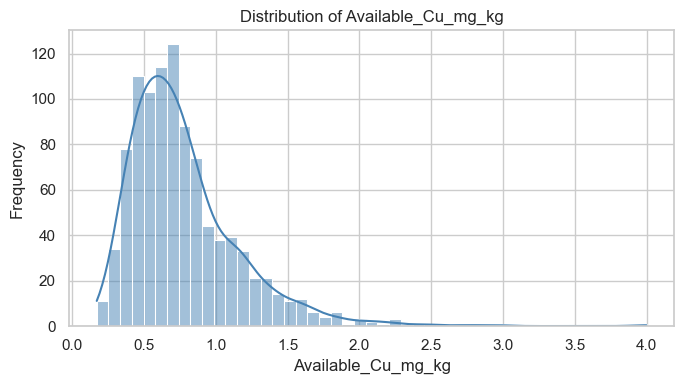

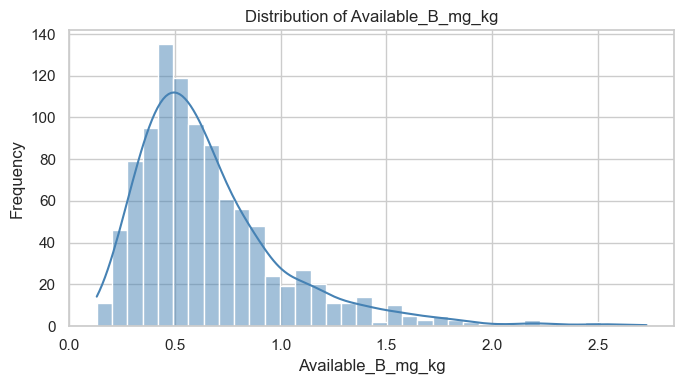

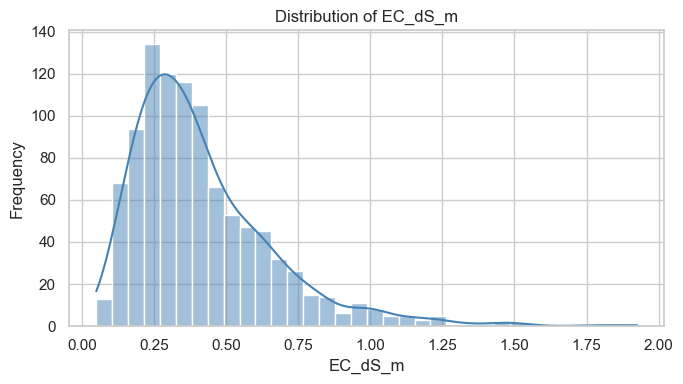

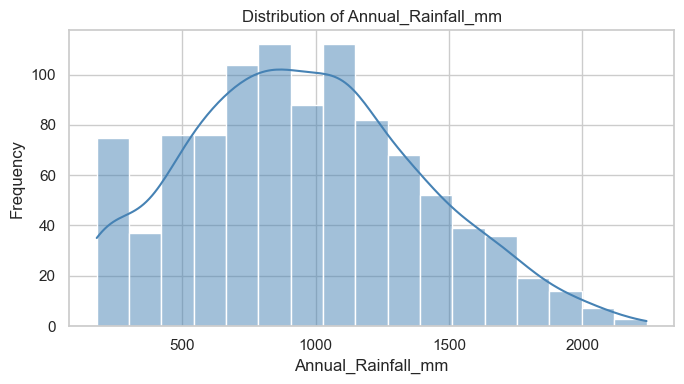

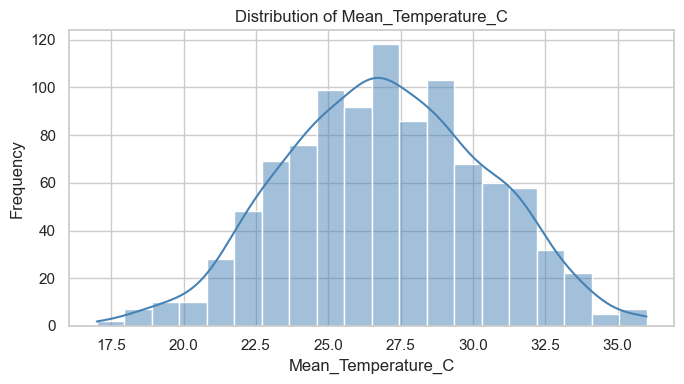

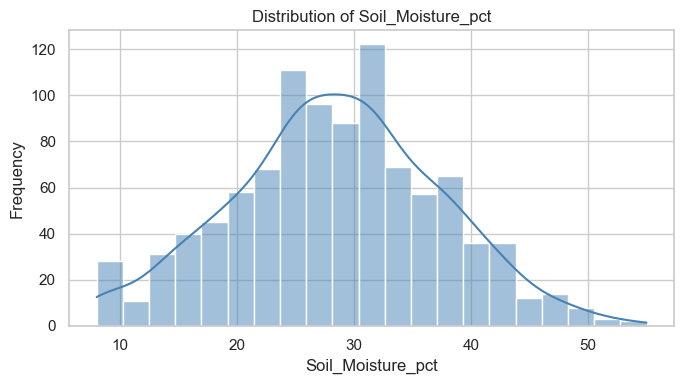

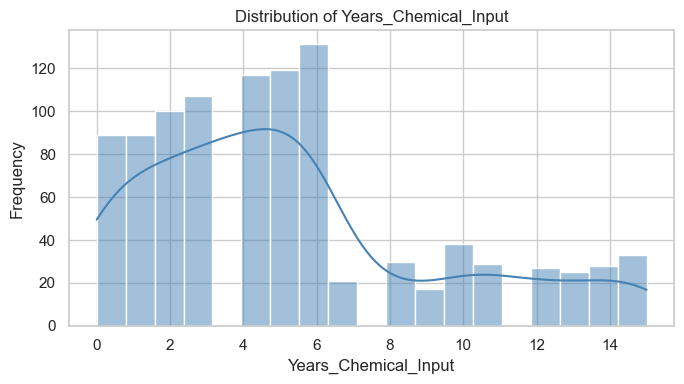

In [10]:
TARGET = "Organic_Farming_Suitability"

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index, color="steelblue")
plt.title("Distribution of Organic Farming Suitability")
plt.xlabel("Suitability Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

numeric_columns_for_eda = df.select_dtypes(include=np.number).columns.tolist()
numeric_columns_for_eda = [c for c in numeric_columns_for_eda if c != "Suitability_Score"]

for column in numeric_columns_for_eda:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[column].dropna(), kde=True, color="steelblue")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

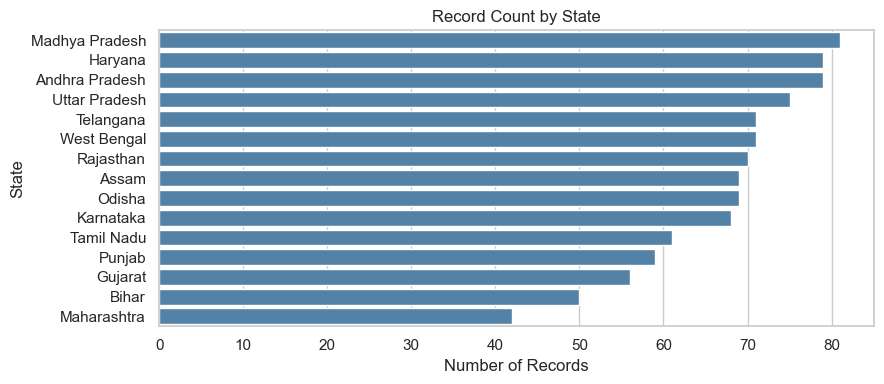

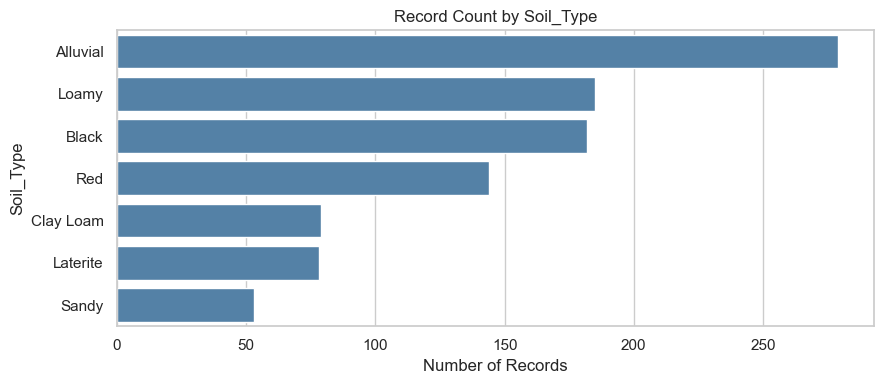

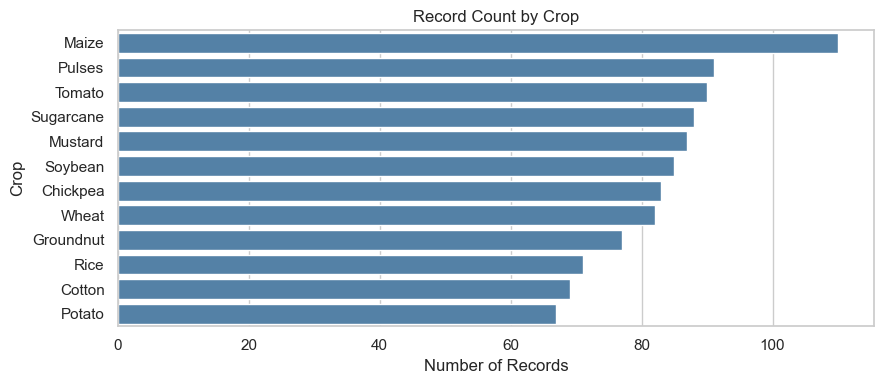

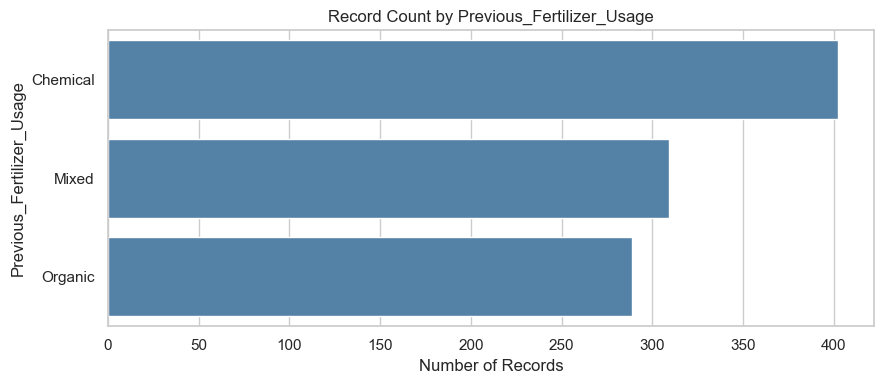

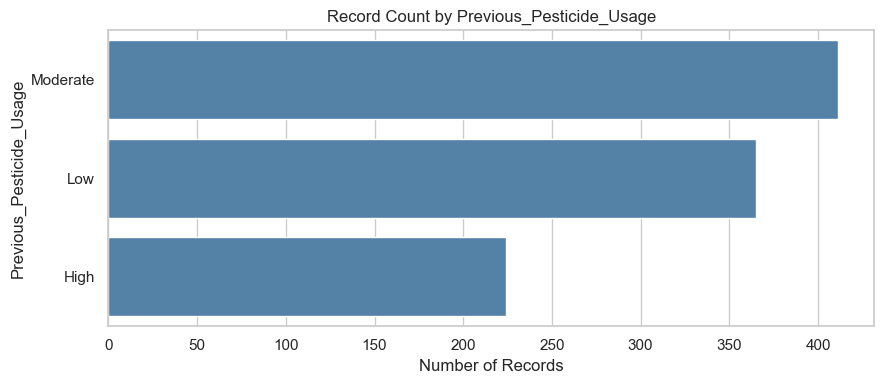

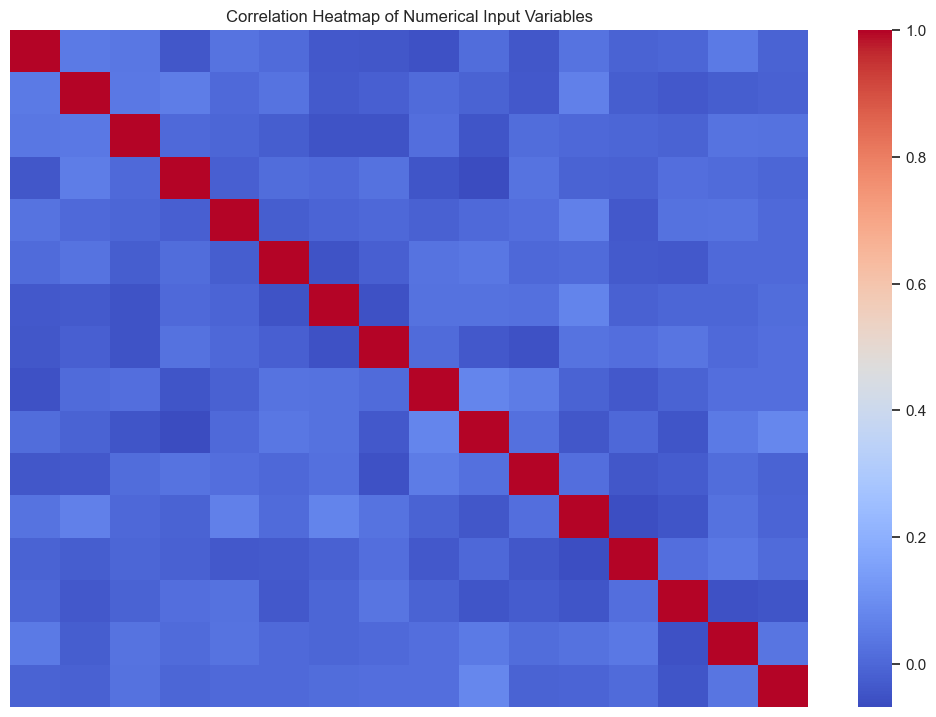

In [9]:
categorical_columns_for_eda = [
    c for c in ["State", "Soil_Type", "Crop",
                "Previous_Fertilizer_Usage", "Previous_Pesticide_Usage"]
    if c in df.columns
]

for column in categorical_columns_for_eda:
    plt.figure(figsize=(9, 4))
    order = df[column].value_counts().index
    sns.countplot(data=df, y=column, order=order, color="steelblue")
    plt.title(f"Record Count by {column}")
    plt.xlabel("Number of Records")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(12, 9))
corr = df.select_dtypes(include=np.number).drop(
    columns=["Suitability_Score"], errors="ignore"
).corr()
sns.heatmap(corr, cmap="coolwarm", annot=False, linewidths=0)
plt.title("Correlation Heatmap of Numerical Input Variables")
plt.tight_layout()
plt.axis(False)
plt.show()

In [10]:
TARGET = "Organic_Farming_Suitability"

columns_to_exclude = [
    TARGET,
    "Suitability_Score",  # Excluded to prevent target leakage
    "Sample_ID"            # Identifier, not a meaningful predictor
]

X = df.drop(columns=columns_to_exclude, errors="ignore")
y_text = df[TARGET].astype(str).str.strip()

# Encode the two labels consistently: Suitable=1 and Not Suitable=0.
label_map = {"Not Suitable": 0, "Suitable": 1}
unexpected_labels = sorted(set(y_text.unique()) - set(label_map))

if unexpected_labels:
    raise ValueError(f"Unexpected target labels found: {unexpected_labels}")

y = y_text.map(label_map)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Input features:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTarget counts:")
display(y_text.value_counts())

Input features: 21
Numerical features: ['pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Years_Chemical_Input']
Categorical features: ['State', 'Soil_Type', 'Crop', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage']

Target counts:


Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 800
Testing records: 200


In [12]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE,
        class_weight="balanced", n_jobs=-1
    )
}

trained_models = {}
results = []
predictions = {}
probabilities = {}

for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    trained_models[model_name] = model_pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("All four models have been trained.")

All four models have been trained.


In [15]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE,
        class_weight="balanced", n_jobs=-1
    )
}

trained_models = {}
results = []
predictions = {}
probabilities = {}

for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    trained_models[model_name] = model_pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("All four models have been trained.")

All four models have been trained.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.7875,0.7412,0.7636,0.8891
1,Random Forest,0.805,0.8108,0.7059,0.7547,0.8842
2,Decision Tree,0.760,0.7033,0.7529,0.7273,0.7591
3,KNN,0.765,0.7714,0.6353,0.6968,0.8144


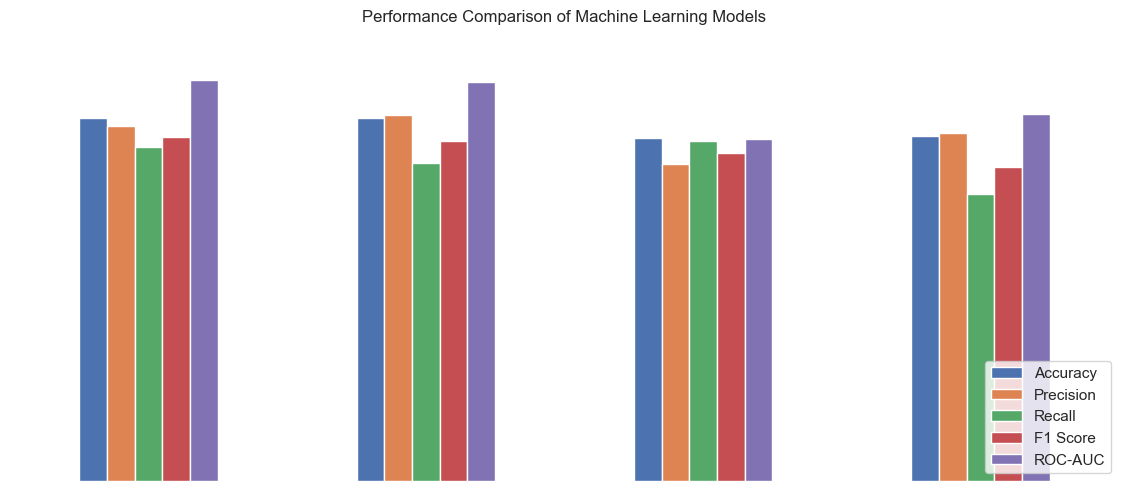

In [16]:
results_df = pd.DataFrame(results).sort_values(
    by=["F1 Score", "ROC-AUC", "Accuracy"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.axis(False)
plt.show()

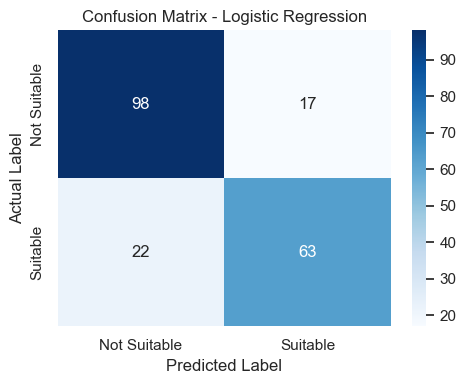

Classification Report - Logistic Regression
              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200



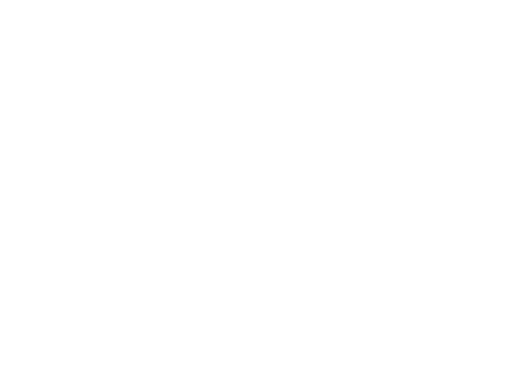

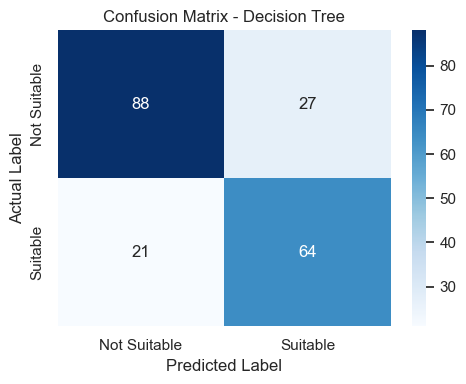

Classification Report - Decision Tree
              precision    recall  f1-score   support

Not Suitable       0.81      0.77      0.79       115
    Suitable       0.70      0.75      0.73        85

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.76      0.76      0.76       200



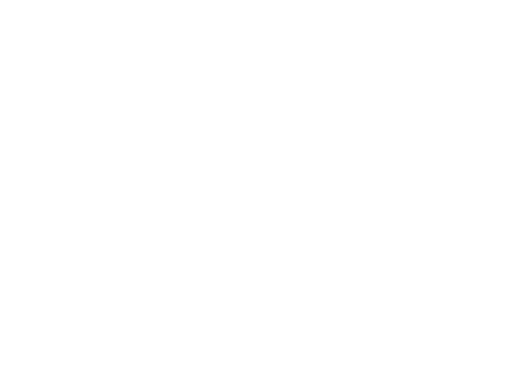

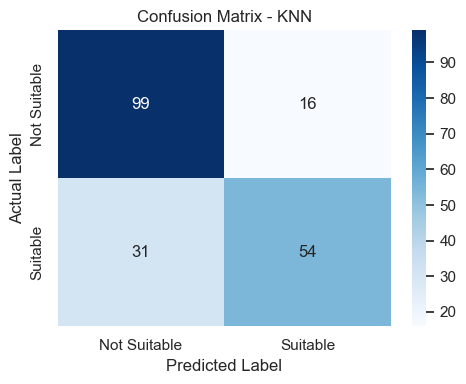

Classification Report - KNN
              precision    recall  f1-score   support

Not Suitable       0.76      0.86      0.81       115
    Suitable       0.77      0.64      0.70        85

    accuracy                           0.77       200
   macro avg       0.77      0.75      0.75       200
weighted avg       0.77      0.77      0.76       200



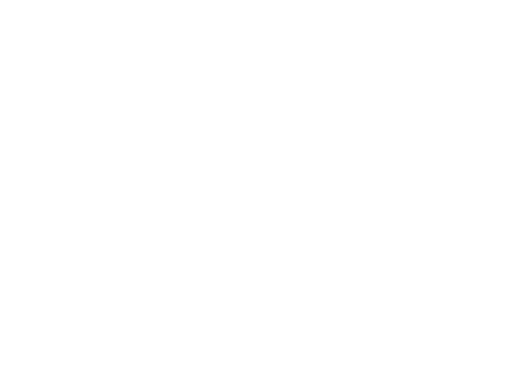

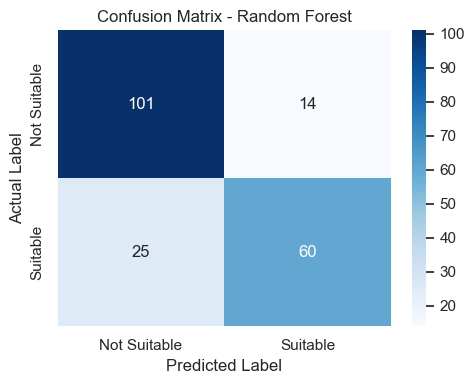

Classification Report - Random Forest
              precision    recall  f1-score   support

Not Suitable       0.80      0.88      0.84       115
    Suitable       0.81      0.71      0.75        85

    accuracy                           0.81       200
   macro avg       0.81      0.79      0.80       200
weighted avg       0.81      0.81      0.80       200



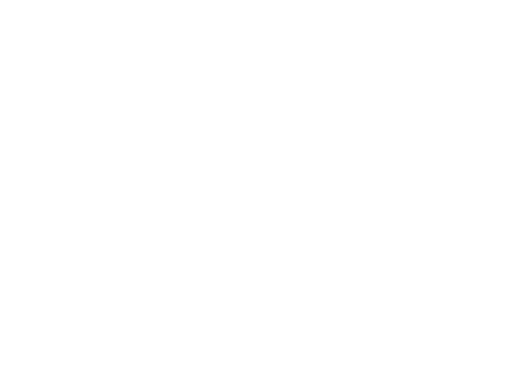

In [21]:
for model_name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Not Suitable", "Suitable"],
        yticklabels=["Not Suitable", "Suitable"],
        linewidths=0
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()
    plt.axis(False)

    print(f"Classification Report - {model_name}")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Not Suitable", "Suitable"],
        zero_division=0
    ))

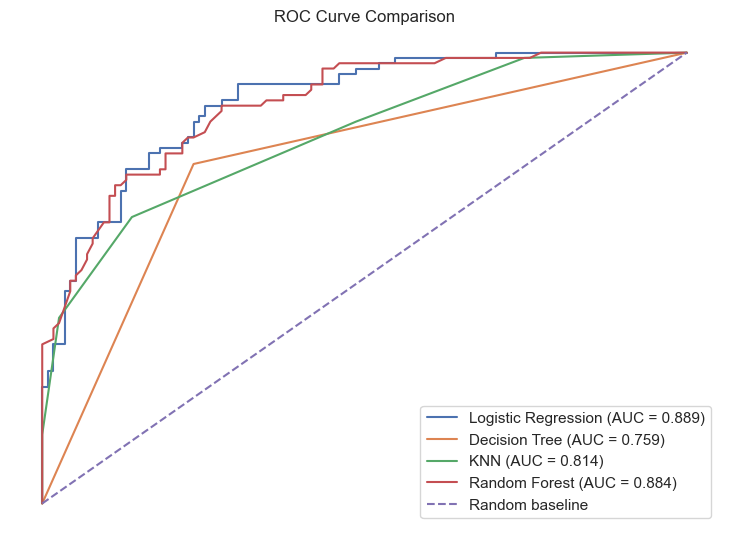

In [19]:
plt.figure(figsize=(8, 6))

for model_name, y_prob in probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.axis(False)
plt.show()

In [22]:
# ============================================================
# CELL 15: SELECT THE BEST MACHINE LEARNING MODEL
# ============================================================

# Select the best model based on F1 Score
best_model_name = results_df.iloc[0]["Model"]

# Retrieve the trained model
best_model = trained_models[best_model_name]

# Display selected model
print("============================================================")
print("          BEST MACHINE LEARNING MODEL")
print("============================================================")

print("\nSelected Model:", best_model_name)

print("\nPerformance Metrics:")

# Display numeric metrics only
best_results = results_df.iloc[0]

print("Accuracy  :", round(best_results["Accuracy"], 4))
print("Precision :", round(best_results["Precision"], 4))
print("Recall    :", round(best_results["Recall"], 4))
print("F1 Score  :", round(best_results["F1 Score"], 4))
print("ROC-AUC   :", round(best_results["ROC-AUC"], 4))

print("\n============================================================")
print("Best model selected successfully!")
print("============================================================")


          BEST MACHINE LEARNING MODEL

Selected Model: Logistic Regression

Performance Metrics:
Accuracy  : 0.805
Precision : 0.7875
Recall    : 0.7412
F1 Score  : 0.7636
ROC-AUC   : 0.8891

Best model selected successfully!


,Feature,Importance_Mean,Importance_Std
4,Organic_Carbon_pct,0.1977,0.0376
3,pH,0.0756,0.0311
6,Available_P_kg_ha,0.0678,0.0179
18,Previous_Fertilizer_Usage,0.0508,0.0204
5,Available_N_kg_ha,0.0445,0.0202
7,Available_K_kg_ha,0.0296,0.0119
19,Previous_Pesticide_Usage,0.0080,0.0186
0,State,0.0046,0.0094
2,Crop,0.0034,0.0123
17,Soil_Moisture_pct,0.0015,0.0030


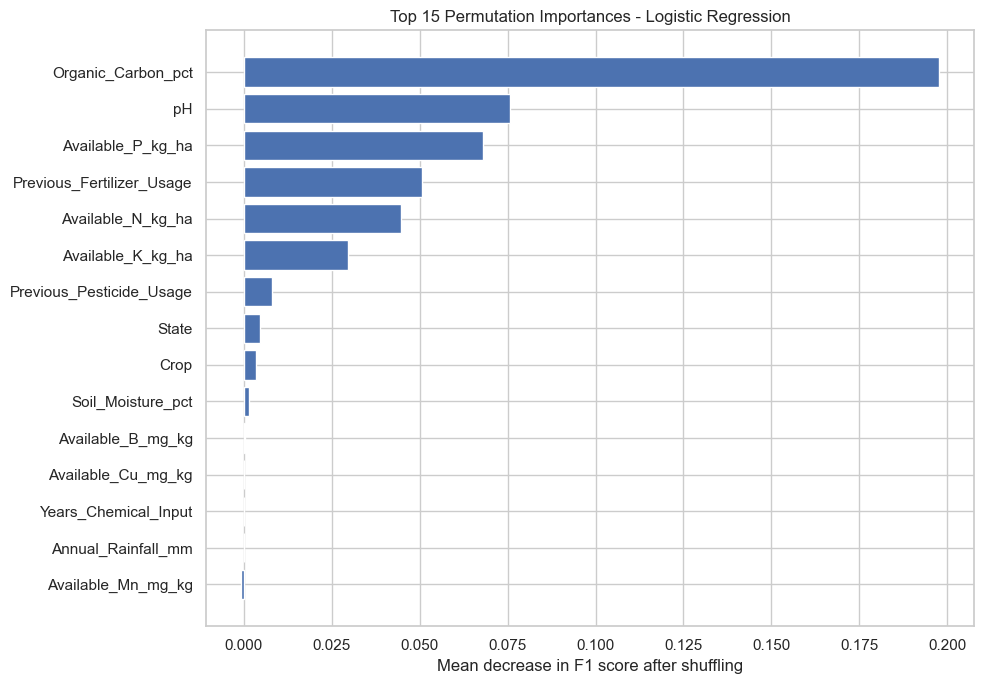

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

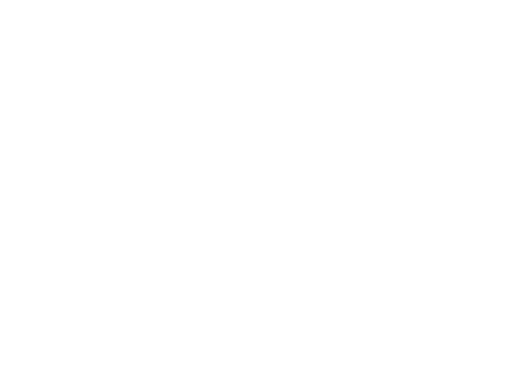

In [23]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance_Mean")
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance_Mean"])
plt.xlabel("Mean decrease in F1 score after shuffling")
plt.title(f"Top 15 Permutation Importances - {best_model_name}")
plt.tight_layout()
plt.show()
plt.axis(False)


In [24]:
MODEL_PATH = "best_organic_farming_model.pkl"
joblib.dump(best_model, MODEL_PATH)
print("Model saved to:", os.path.abspath(MODEL_PATH))

Model saved to: C:\Users\Deboprio Roy\new\Untitled Folder\best_organic_farming_model.pkl


In [25]:
new_record = X_test.iloc[[0]].copy()

predicted_class = best_model.predict(new_record)[0]
predicted_probability = best_model.predict_proba(new_record)[0, 1]

label_name = "Suitable" if predicted_class == 1 else "Not Suitable"

print("Predicted class:", label_name)
print(f"Estimated model probability for Suitable: {predicted_probability:.3f}")
display(new_record)

Predicted class: Suitable
Estimated model probability for Suitable: 1.000


,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,...,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input
484,Madhya Pradesh,Alluvial,Soybean,6.8,1.546,168.6,36.7,434.5,24.21,0.67,...,6.21,1.0,1.28,0.48,205.3,30.0,25.6,Organic,Low,1
